In [1]:
# for package auto reload
%load_ext autoreload
%autoreload 2

# for better rendering of plots in jupyter notebook
%matplotlib inline

In [2]:
# for ml
from sklearn.linear_model import LinearRegression

In [3]:
# base modules
from pathlib import Path

# for manipulating data
import numpy as np
import pandas as pd

# forMachine Learning
from sklearn.ensemble import RandomForestRegressor

#for plots
import seaborn as sns


In [4]:
# base modules
from pathlib import Path
import logging
from collections import OrderedDict

# for manipulating data
import numpy as np
import pandas as pd
import math
import dill

# for Machine Learning
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn import metrics
from sklearn.model_selection import cross_val_score, KFold, GridSearchCV

# for visualization
from matplotlib import pyplot as plt

In [5]:
from eclyon.transforms import (
    add_date_columns, 
    change_columns_from_str_to_categorical, 
    process_df,
)

In [6]:
# --- extra imports for the new cells ---
import scipy
from collections import defaultdict
from scipy.cluster import hierarchy

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance

from eclyon.transforms import process_df, split_vals
from eclyon.explain import rf_feat_importance

In [7]:
df_raw = pd.read_csv(r'data.csv')

In [8]:
def display_all(df):
    with pd.option_context("display.max_rows", 50, "display.max_columns", 50): 
        display(df)

In [9]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  object 
 1   Customer Type                      129880 non-null  object 
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  object 
 4   Class                              129880 non-null  object 
 5   Flight Distance                    129880 non-null  int64  
 6   Inflight wifi service              129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Ease of Online booking             129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Food and drink                     129880 non-null  int64  
 11  Online boarding                    1298

In [10]:
df_raw = df_raw.convert_dtypes()

In [11]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  string 
 1   Customer Type                      129880 non-null  string 
 2   Age                                129880 non-null  Int64  
 3   Type of Travel                     129880 non-null  string 
 4   Class                              129880 non-null  string 
 5   Flight Distance                    129880 non-null  Int64  
 6   Inflight wifi service              129880 non-null  Int64  
 7   Departure/Arrival time convenient  129880 non-null  Int64  
 8   Ease of Online booking             129880 non-null  Int64  
 9   Gate location                      129880 non-null  Int64  
 10  Food and drink                     129880 non-null  Int64  
 11  Online boarding                    1298

In [12]:
df_raw

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0,True
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,Male,disloyal Customer,34,Business travel,Business,526,3,3,3,1,...,4,4,3,2,4,4,4,0,0,False
129876,Male,Loyal Customer,23,Business travel,Business,646,4,4,4,4,...,4,4,4,5,5,5,4,0,0,True
129877,Female,Loyal Customer,17,Personal Travel,Eco,828,2,5,1,5,...,2,2,4,3,4,5,2,0,0,False
129878,Male,Loyal Customer,14,Business travel,Business,1127,3,3,3,3,...,4,4,3,2,5,4,4,0,0,True


In [13]:
df_raw.columns


Index(['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class',
       'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction'],
      dtype='object')

In [14]:
df_raw.shape

(129880, 22)

In [15]:
df_raw.satisfaction

0         False
1         False
2          True
3         False
4          True
          ...  
129875    False
129876     True
129877    False
129878     True
129879    False
Name: satisfaction, Length: 129880, dtype: boolean

In [16]:
satisfaction = df_raw.satisfaction.tolist()


In [17]:
df_raw.describe(include = 'all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Gender,129880,2,Female,65899,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Type,129880,2,Loyal Customer,106100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,129880.0,<NA>,<NA>,<NA>,39.427957,15.11936,7.0,27.0,40.0,51.0,85.0
Type of Travel,129880,2,Business travel,89693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Class,129880,3,Business,62160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flight Distance,129880.0,<NA>,<NA>,<NA>,1190.316392,997.452477,31.0,414.0,844.0,1744.0,4983.0
Inflight wifi service,129880.0,<NA>,<NA>,<NA>,2.728696,1.32934,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,129880.0,<NA>,<NA>,<NA>,3.057599,1.526741,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,129880.0,<NA>,<NA>,<NA>,2.756876,1.40174,0.0,2.0,3.0,4.0,5.0
Gate location,129880.0,<NA>,<NA>,<NA>,2.976925,1.27852,0.0,2.0,3.0,4.0,5.0


In [18]:
df_transformed = change_columns_from_str_to_categorical(df_raw)

In [19]:
df_transformed.satisfaction

0         False
1         False
2          True
3         False
4          True
          ...  
129875    False
129876     True
129877    False
129878     True
129879    False
Name: satisfaction, Length: 129880, dtype: boolean

In [20]:
display_all(df_transformed.isnull().sum().T) 

Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             393
satisfaction                           0
dtype: int64

In [21]:
df_transformed.isnull().describe()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
count,129880,129880,129880,129880,129880,129880,129880,129880,129880,129880,...,129880,129880,129880,129880,129880,129880,129880,129880,129880,129880
unique,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,2,1
top,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
freq,129880,129880,129880,129880,129880,129880,129880,129880,129880,129880,...,129880,129880,129880,129880,129880,129880,129880,129880,129487,129880


In [22]:
display_all(df_transformed.isnull().sum().sort_index()/len(df_transformed))

Age                                  0.000000
Arrival Delay in Minutes             0.003026
Baggage handling                     0.000000
Checkin service                      0.000000
Class                                0.000000
Cleanliness                          0.000000
Customer Type                        0.000000
Departure Delay in Minutes           0.000000
Departure/Arrival time convenient    0.000000
Ease of Online booking               0.000000
Flight Distance                      0.000000
Food and drink                       0.000000
Gate location                        0.000000
Gender                               0.000000
Inflight entertainment               0.000000
Inflight wifi service                0.000000
Leg room service                     0.000000
On-board service                     0.000000
Online boarding                      0.000000
Seat comfort                         0.000000
Type of Travel                       0.000000
satisfaction                      

## 1. Pitch of the data: volume, features, quality

In [23]:
print('Volume   : {} rows x {} columns'.format(*df_raw.shape))
print('Target   : satisfaction  ->  share of satisfied passengers = {:.1%}'.format(df_raw.satisfaction.mean()))
print()
print(df_raw.dtypes.astype(str).value_counts())

Volume   : 129880 rows x 22 columns
Target   : satisfaction  ->  share of satisfied passengers = 43.4%

Int64      17
string      4
boolean     1
Name: count, dtype: int64


In [24]:
# Quality 1: missing values
missing = df_transformed.isnull().sum()
missing[missing > 0]

Arrival Delay in Minutes    393
dtype: int64

In [25]:
# Are rows with a missing Arrival Delay different from the others?
na_rows = df_transformed['Arrival Delay in Minutes'].isnull()
print('Rows with missing Arrival Delay:', na_rows.sum())
print('Satisfied rate (missing rows): {:.1%}'.format(df_transformed.loc[na_rows, 'satisfaction'].astype(int).mean()))
print('Satisfied rate (all rows)    : {:.1%}'.format(df_transformed['satisfaction'].astype(int).mean()))

Rows with missing Arrival Delay: 393
Satisfied rate (missing rows): 42.2%
Satisfied rate (all rows)    : 43.4%


In [26]:
# Is the order of the rows meaningful? (needed to justify split_vals)
sat = df_transformed['satisfaction'].astype(int).values
cut = int(len(sat) * 0.8)
print('Satisfied rate, first 80% of rows: {:.1%}'.format(sat[:cut].mean()))
print('Satisfied rate, last 20% of rows : {:.1%}'.format(sat[cut:].mean()))

Satisfied rate, first 80% of rows: 43.3%
Satisfied rate, last 20% of rows : 43.9%


## 2. Numericalize categoricals
The Class column is ordered (Eco < Eco Plus < Business), so we set the order by hand like UsageBand (lab 2)

In [27]:
df_transformed['Class'] = df_transformed['Class'].cat.set_categories(['Eco', 'Eco Plus', 'Business'], ordered = True)
df_transformed['Class'] = df_transformed['Class'].cat.codes
df_transformed['Class'].value_counts().sort_index()

Class
0    58309
1     9411
2    62160
Name: count, dtype: int64

## 3. Fill missing values

In [28]:
df_transformed = df_transformed.dropna()
display_all(df_transformed.isnull().sum().T) 

Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                         0
dtype: int64

## 4. Split

In [29]:
df, y, nas = process_df(df_transformed, 'satisfaction')

In [30]:
n_total = len(df_transformed)
n_valid = 26000
n_train = n_total - n_valid
n_small = 20000

X_train, X_valid = split_vals(df_transformed, n_train)
y_train, y_valid = split_vals(y, n_train)

X_small, _ = split_vals(df_transformed, n_small)
y_small, _ = split_vals(y, n_small)

print('Small training data: X = {}, y = {}'.format(X_small.shape, y_small.shape))
print('Full training data : X = {}, y = {}'.format(X_train.shape, y_train.shape))
print('Validation data    : X = {}, y = {}'.format(X_valid.shape, y_valid.shape))

Small training data: X = (20000, 22), y = (20000,)
Full training data : X = (103487, 22), y = (103487,)
Validation data    : X = (26000, 22), y = (26000,)


## 5. First models: decision trees (lab 4)

In [36]:
df_transformed = change_columns_from_str_to_categorical(df_transformed)

In [37]:
# effect of depth
for depth in [3, 6, 10, None]:
    tree = DecisionTreeClassifier(criterion = 'gini', max_depth = depth, random_state = 42)
    tree.fit(X_small, y_small)
    print('max_depth = {!s:5} | train acc = {:.3f} | valid acc = {:.3f}'.format(
        depth, tree.score(X_small, y_small), tree.score(X_valid, y_valid)))

ValueError: Cannot cast string dtype to float32

In [39]:
# effect of the criterion
for crit in ['gini', 'entropy']:
    tree = DecisionTreeClassifier(criterion = crit, max_depth = 10, random_state = 42)
    tree.fit(X_small, y_small)
    print('criterion = {:8} | valid acc = {:.3f}'.format(crit, tree.score(X_valid, y_valid)))

criterion = gini     | valid acc = 0.936
criterion = entropy  | valid acc = 0.935


## 6. Random forests (lab 4): depth, feature sampling, data sampling, OOB

In [38]:
def run_forest(name, X_tr, y_tr, X_va, y_va, **params):
    rf = RandomForestClassifier(n_estimators = 50, oob_score = True, n_jobs = -1, random_state = 42, **params)
    rf.fit(X_tr, y_tr)
    print('{:40} | train {:.3f} | valid {:.3f} | oob {:.3f}'.format(
        name, rf.score(X_tr, y_tr), rf.score(X_va, y_va), rf.oob_score_))
    return rf

rf = run_forest('max_depth = 10',                 X_small, y_small, X_valid, y_valid, max_depth = 10)
rf = run_forest('no depth limit',                 X_small, y_small, X_valid, y_valid)
rf = run_forest('+ max_features = 0.5, leaf = 3', X_small, y_small, X_valid, y_valid, max_features = 0.5, min_samples_leaf = 3)
rf = run_forest('+ max_samples = 0.5',            X_small, y_small, X_valid, y_valid, max_features = 0.5, min_samples_leaf = 3, max_samples = 0.5)

ValueError: Cannot cast string dtype to float32

In [39]:
# final forest on the full training set
model = RandomForestClassifier(
    n_estimators = 100, max_features = 0.5, min_samples_leaf = 3,
    oob_score = True, n_jobs = -1, random_state = 42,
)
%time model.fit(X_train, y_train)

print('train acc: {:.3f}'.format(model.score(X_train, y_train)))
print('valid acc: {:.3f}'.format(model.score(X_valid, y_valid)))
print('oob acc  : {:.3f}'.format(model.oob_score_))

ValueError: Cannot cast string dtype to float32

AttributeError: 'RandomForestClassifier' object has no attribute 'estimators_'

## 7. Sound statistical decisions: cross-validation, small grid search, precision / recall

In [42]:
kf = KFold(n_splits = 5, shuffle = True, random_state = 42)
scores = cross_val_score(model, X_small, y_small, cv = kf, n_jobs = -1)

print(scores)
print('accuracy is {:.3f} with a standard deviation of {:.3f}'.format(scores.mean(), scores.std()))

[0.956   0.9425  0.951   0.9535  0.94975]
accuracy is 0.951 with a standard deviation of 0.005


In [43]:
param_grid = {'max_features': [0.3, 0.5, 0.8], 'min_samples_leaf': [1, 3, 10]}
grid = GridSearchCV(
    RandomForestClassifier(n_estimators = 50, n_jobs = -1, random_state = 42),
    param_grid, cv = 3, n_jobs = 1,
)
grid.fit(X_small, y_small)

print(grid.best_params_, '-> cv accuracy {:.3f}'.format(grid.best_score_))

{'max_features': 0.5, 'min_samples_leaf': 1} -> cv accuracy 0.950


In [44]:
y_pred = model.predict(X_valid)
print(metrics.classification_report(y_valid, y_pred, target_names = ['neutral/dissatisfied', 'satisfied']))

                      precision    recall  f1-score   support

neutral/dissatisfied       0.95      0.98      0.97     14587
           satisfied       0.97      0.94      0.95     11413

            accuracy                           0.96     26000
           macro avg       0.96      0.96      0.96     26000
        weighted avg       0.96      0.96      0.96     26000



## 8. Interpret the model (lab 5)

In [45]:
feat_importance = rf_feat_importance(model, X_train)
feat_importance[:20]

,cols,imp
11,Online boarding,0.297605
6,Inflight wifi service,0.170575
3,Type of Travel,0.110333
4,Class,0.089898
13,Inflight entertainment,0.049330
1,Customer Type,0.036563
15,Leg room service,0.025982
12,Seat comfort,0.025607
2,Age,0.024784
8,Ease of Online booking,0.024282


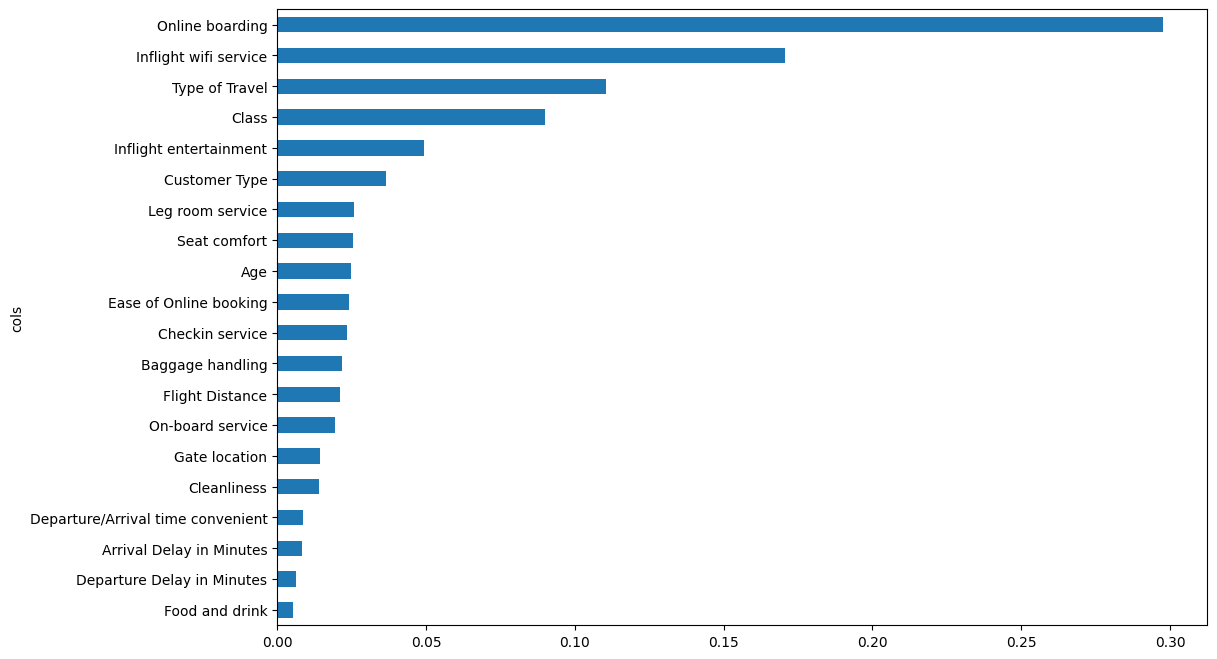

In [46]:
barh = feat_importance[:20].plot('cols', 'imp', 'barh', figsize = (12, 8), legend = False)
barh = barh.invert_yaxis()
barh

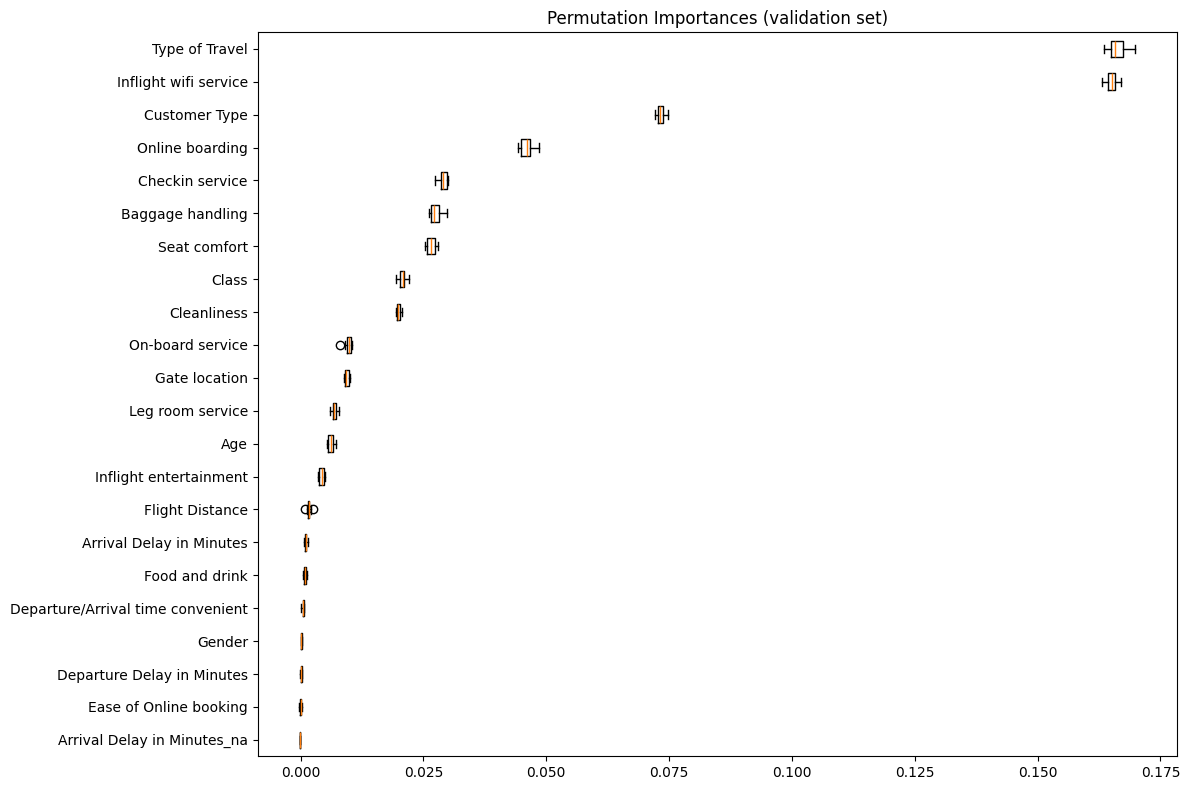

In [47]:
result = permutation_importance(model, X_valid, y_valid, n_repeats = 10, random_state = 42, n_jobs = -1)
sorted_idx = result.importances_mean.argsort()

fig, ax = plt.subplots(figsize = (12, 8))
ax.boxplot(result.importances[sorted_idx].T, vert = False, tick_labels = X_valid.columns[sorted_idx])
ax.set_title('Permutation Importances (validation set)')
fig.tight_layout()
plt.show()

In [48]:
# compare the two rankings side by side
perm = pd.Series(result.importances_mean, index = X_valid.columns).sort_values(ascending = False)
pd.DataFrame({
    'impurity importance' : feat_importance.set_index('cols').imp,
    'permutation importance' : perm,
}).sort_values('permutation importance', ascending = False).round(3)

,impurity importance,permutation importance
Type of Travel,0.110,0.166
Inflight wifi service,0.171,0.165
Customer Type,0.037,0.073
Online boarding,0.298,0.046
Checkin service,0.024,0.029
Baggage handling,0.022,0.027
Seat comfort,0.026,0.027
Class,0.090,0.021
Cleanliness,0.014,0.020
On-board service,0.019,0.010
